In [4]:
# ============================================
# SentinelSys - Intelligent Infrastructure Health Advisor
# Fuzzy Controller Version 1.0
# ============================================
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:


import numpy as np
from skfuzzy import control as ctrl

# -------- INPUT VARIABLES --------

cpu_temp = ctrl.Antecedent(np.arange(20, 101, 1), 'cpu_temp')

cpu_usage = ctrl.Antecedent(np.arange(0, 101, 1), 'cpu_usage')

ram_usage = ctrl.Antecedent(np.arange(0, 101, 1), 'ram_usage')

disk_usage = ctrl.Antecedent(np.arange(0, 101, 1), 'disk_usage')

fan_speed = ctrl.Antecedent(np.arange(500, 4001, 1), 'fan_speed')

uptime = ctrl.Antecedent(np.arange(0, 366, 1), 'uptime')

# -------- OUTPUT VARIABLE --------

maintenance = ctrl.Consequent(
    np.arange(0, 101, 1),
    'maintenance'
)

print(" All fuzzy variables created successfully!")

✅ All fuzzy variables created successfully!


In [6]:

# LOW
cpu_temp['Low'] = fuzz.trimf(
    cpu_temp.universe,
    [20, 20, 50]
)

# NORMAL
cpu_temp['Normal'] = fuzz.trimf(
    cpu_temp.universe,
    [35, 60, 80]
)

# HIGH
cpu_temp['High'] = fuzz.trimf(
    cpu_temp.universe,
    [65, 100, 100]
)

print(" CPU Temperature membership functions created!")

 CPU Temperature membership functions created!


c:\Users\LENOVO\Desktop\SentinelSys\.venv\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


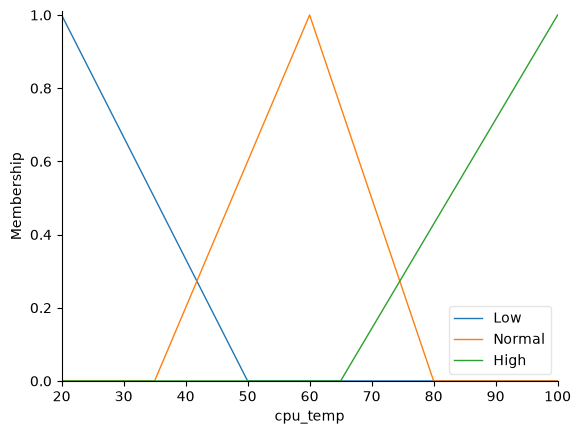

In [7]:
cpu_temp.view()

In [8]:

# ---------------- CPU USAGE ----------------

cpu_usage['Low'] = fuzz.trimf(cpu_usage.universe, [0, 0, 50])
cpu_usage['Medium'] = fuzz.trimf(cpu_usage.universe, [25, 50, 75])
cpu_usage['High'] = fuzz.trimf(cpu_usage.universe, [50, 100, 100])

# ---------------- RAM USAGE ----------------

ram_usage['Low'] = fuzz.trimf(ram_usage.universe, [0, 0, 50])
ram_usage['Medium'] = fuzz.trimf(ram_usage.universe, [25, 50, 75])
ram_usage['High'] = fuzz.trimf(ram_usage.universe, [50, 100, 100])

# ---------------- DISK USAGE ----------------

disk_usage['Low'] = fuzz.trimf(disk_usage.universe, [0, 0, 50])
disk_usage['Medium'] = fuzz.trimf(disk_usage.universe, [25, 50, 75])
disk_usage['High'] = fuzz.trimf(disk_usage.universe, [50, 100, 100])

# ---------------- FAN SPEED ----------------

fan_speed['Slow'] = fuzz.trimf(fan_speed.universe, [500, 500, 1800])
fan_speed['Normal'] = fuzz.trimf(fan_speed.universe, [1500, 2500, 3200])
fan_speed['Fast'] = fuzz.trimf(fan_speed.universe, [2800, 4000, 4000])

# ---------------- UPTIME ----------------

uptime['Short'] = fuzz.trimf(uptime.universe, [0, 0, 100])
uptime['Medium'] = fuzz.trimf(uptime.universe, [80, 180, 280])
uptime['Long'] = fuzz.trimf(uptime.universe, [250, 365, 365])

# ---------------- OUTPUT ----------------

maintenance['Healthy'] = fuzz.trimf(maintenance.universe, [0, 0, 20])

maintenance['Monitor'] = fuzz.trimf(maintenance.universe, [15, 30, 45])

maintenance['Cleaning'] = fuzz.trimf(maintenance.universe, [40, 55, 70])

maintenance['Maintenance'] = fuzz.trimf(maintenance.universe, [65, 80, 90])

maintenance['Critical'] = fuzz.trimf(maintenance.universe, [85, 100, 100])

print(" All Membership Functions Created Successfully!")

 All Membership Functions Created Successfully!


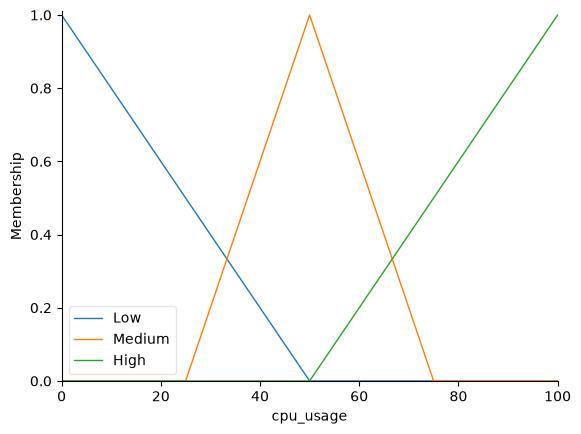

In [9]:
cpu_usage.view()

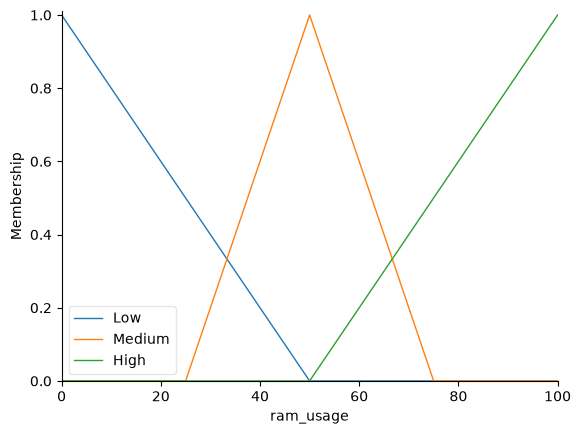

In [10]:
ram_usage.view()

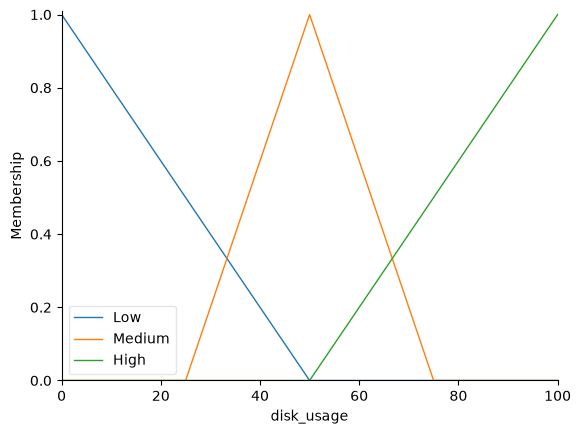

In [11]:
disk_usage.view()

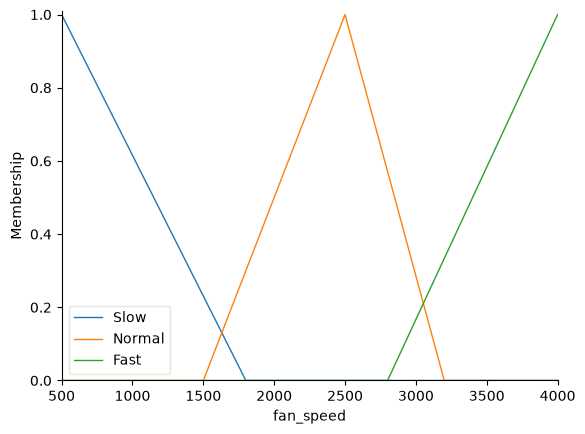

In [12]:
fan_speed.view()

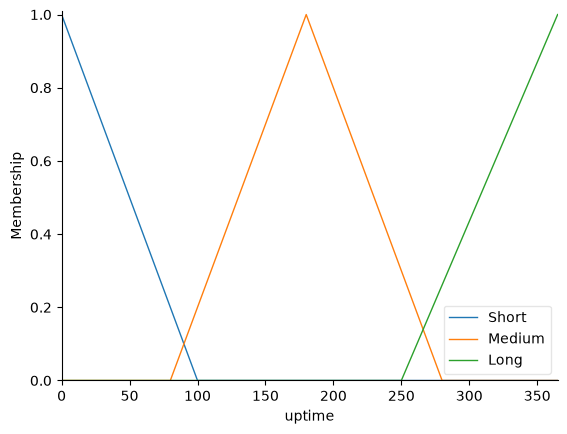

In [13]:
uptime.view()

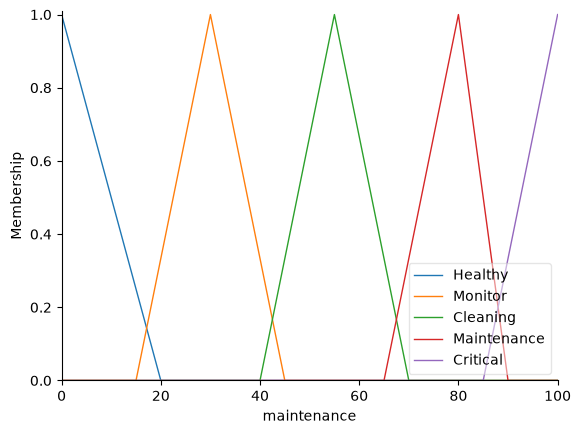

In [14]:
maintenance.view()

In [16]:
rule1 = ctrl.Rule(cpu_temp['High'], maintenance['Critical'])

rule2 = ctrl.Rule(cpu_temp['Normal'], maintenance['Monitor'])

rule3 = ctrl.Rule(cpu_temp['Low'], maintenance['Healthy'])

rule4 = ctrl.Rule(cpu_temp['High'] & fan_speed['Slow'],
                  maintenance['Critical'])

rule5 = ctrl.Rule(cpu_temp['High'] & cpu_usage['High'],
                  maintenance['Critical'])
rule6 = ctrl.Rule(cpu_usage['High'],
                  maintenance['Maintenance'])

rule7 = ctrl.Rule(cpu_usage['Medium'],
                  maintenance['Monitor'])

rule8 = ctrl.Rule(cpu_usage['Low'],
                  maintenance['Healthy'])

rule9 = ctrl.Rule(cpu_usage['High'] & ram_usage['High'],
                  maintenance['Maintenance'])

rule10 = ctrl.Rule(cpu_usage['High'] & disk_usage['High'],
                   maintenance['Critical'])
rule11 = ctrl.Rule(ram_usage['High'],
                   maintenance['Maintenance'])

rule12 = ctrl.Rule(ram_usage['Medium'],
                   maintenance['Cleaning'])

rule13 = ctrl.Rule(ram_usage['Low'],
                   maintenance['Healthy'])

rule14 = ctrl.Rule(ram_usage['High'] & uptime['Long'],
                   maintenance['Maintenance'])

rule15 = ctrl.Rule(ram_usage['High'] & cpu_temp['High'],
                   maintenance['Critical'])
rule16 = ctrl.Rule(disk_usage['High'],
                   maintenance['Maintenance'])

rule17 = ctrl.Rule(disk_usage['Medium'],
                   maintenance['Cleaning'])

rule18 = ctrl.Rule(disk_usage['Low'],
                   maintenance['Healthy'])

rule19 = ctrl.Rule(disk_usage['High'] & uptime['Long'],
                   maintenance['Maintenance'])

rule20 = ctrl.Rule(disk_usage['High'] & cpu_usage['High'],
                   maintenance['Critical'])
rule21 = ctrl.Rule(fan_speed['Slow'],
                   maintenance['Maintenance'])

rule22 = ctrl.Rule(fan_speed['Normal'],
                   maintenance['Healthy'])

rule23 = ctrl.Rule(fan_speed['Fast'],
                   maintenance['Monitor'])

rule24 = ctrl.Rule(fan_speed['Slow'] & cpu_temp['High'],
                   maintenance['Critical'])

rule25 = ctrl.Rule(fan_speed['Fast'] & cpu_temp['Normal'],
                   maintenance['Monitor'])
rule26 = ctrl.Rule(uptime['Long'],
                   maintenance['Maintenance'])

rule27 = ctrl.Rule(uptime['Medium'],
                   maintenance['Monitor'])

rule28 = ctrl.Rule(uptime['Short'],
                   maintenance['Healthy'])

rule29 = ctrl.Rule(uptime['Long'] & cpu_temp['High'],
                   maintenance['Critical'])

rule30 = ctrl.Rule(uptime['Long'] &
                   cpu_usage['High'] &
                   ram_usage['High'],
                   maintenance['Critical'])

In [18]:
# Create the Fuzzy Control System
system = ctrl.ControlSystem([
    rule1, rule2, rule3, rule4, rule5,
    rule6, rule7, rule8, rule9, rule10,
    rule11, rule12, rule13, rule14, rule15,
    rule16, rule17, rule18, rule19, rule20,
    rule21, rule22, rule23, rule24, rule25,
    rule26, rule27, rule28, rule29, rule30
])

# Create a Simulation Object
simulation = ctrl.ControlSystemSimulation(system)

print("Control System Ready!")

Control System Ready!


In [19]:



# Input Values
simulation.input['cpu_temp'] = 82
simulation.input['cpu_usage'] = 90
simulation.input['ram_usage'] = 75
simulation.input['disk_usage'] = 85
simulation.input['fan_speed'] = 1200
simulation.input['uptime'] = 300

# Run the Fuzzy Controller
simulation.compute()

# Display Output
print("Maintenance Priority:", round(simulation.output['maintenance'], 2))

Maintenance Priority: 84.12


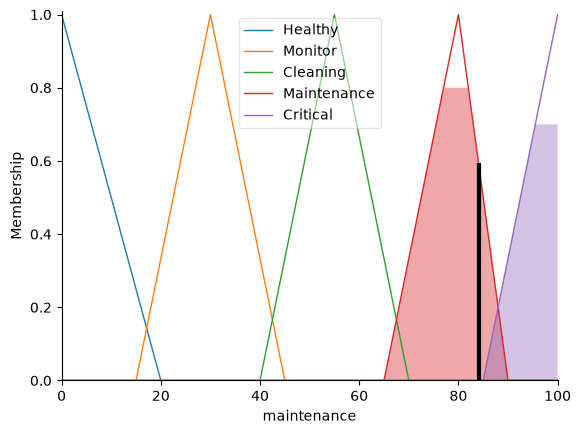

In [20]:
maintenance.view(sim=simulation)